# Non-linear static analysis with the arc-length methods

The arc-length methods, described in
[arc_length._solver_arc_length](../arc_length.rst), trace equilibrium
paths that include limit points, where the Newton-Raphson method with load
control fails. The equilibrium path
$\boldsymbol{F}_{int}(\boldsymbol{c}) = \lambda \boldsymbol{F}_{ext}$ is
traced in steps whose load factor $\lambda$ is an unknown, besides the
solution vector $\boldsymbol{c}$, with the constraint

$$
\frac{\Delta \boldsymbol{c}^\top \Delta \boldsymbol{c}}{\boldsymbol{u}_{ref}^\top \boldsymbol{u}_{ref}}
+ \psi^2 \Delta\lambda^2 = \Delta s^2
$$

on the increments $(\Delta \boldsymbol{c}, \Delta\lambda)$ of the step,
where $\boldsymbol{u}_{ref}$ is the linear solution for $\lambda = 1$ and
$\Delta s$ the arc length. Each iteration solves the bordered system
$\boldsymbol{K}_T \delta \boldsymbol{c} - \delta\lambda \, \boldsymbol{F}_{ext} = -\boldsymbol{R}$
and takes the correction of the load factor $\delta\lambda$ from the
constraint:

- `NL_method='arc_length_riks'`: the constraint linearized at the current
  increment (updated normal plane), Newton's method on the equilibrium
  equations augmented with the constraint, Riks (1979);
- `NL_method='arc_length_crisfield'`: the spherical constraint solved
  exactly, the root of the quadratic equation with the smallest angle to the
  current increment, Crisfield (1981).

Each step starts from the tangent predictor, in the direction of the
previous increment, which lets the path pass the limit points.

References: Riks, E., An incremental approach to the solution of snapping
and buckling problems, International Journal of Solids and Structures,
15(7), 529-551, 1979, https://doi.org/10.1016/0020-7683(79)90081-7;
Crisfield, M.A., A fast incremental/iterative solution procedure that
handles "snap-through", Computers & Structures, 13(1-3), 55-62, 1981,
https://doi.org/10.1016/0045-7949(81)90108-5; Crisfield, M.A., Non-linear
Finite Element Analysis of Solids and Structures, Volume 1: Essentials,
Wiley, 1991, Section 9.3.2.

In [1]:
%matplotlib inline
import os
import sys

# the helper functions of the tests are imported from the folder tests/
sys.path.insert(0, os.path.join('..', 'tests'))

import numpy as np
import matplotlib.pyplot as plt

from analytic_problems import von_mises_truss

METHODS = ['arc_length_riks', 'arc_length_crisfield']

## The model: a shallow von Mises truss loaded through a spring

The shallow von Mises truss of `tests/analytic_problems.py` (height 1) has
the apex deflection $w$ (DOF 0) and the internal force

$$
f(w) = w^3 - 3 w^2 + 2 w = w (w - 1) (w - 2)
$$

It is loaded through a linear spring of stiffness $k_s$ between the apex and
the loaded point, of displacement $u$ (DOF 1), under the force
$\lambda \alpha F_{lim}$, a multiple $\alpha$ of the limit load. The
equilibrium equations $f(w) + k_s (w - u) = 0$ and
$k_s (u - w) = \lambda \alpha F_{lim}$ give the equilibrium path in closed
form, parametrized by $w$:

$$
\lambda(w) = \frac{f(w)}{\alpha F_{lim}}, \qquad
u(w) = w + \frac{f(w)}{k_s}
$$

The truss softens until the limit point $f'(w) = 3 w^2 - 6 w + 2 = 0$,

$$
w_{lim} = 1 - \frac{1}{\sqrt{3}}, \qquad
F_{lim} = f(w_{lim}) = \frac{2}{3 \sqrt{3}}
$$

snaps through to the second limit point, $w = 1 + 1/\sqrt{3}$,
$f = -F_{lim}$, and stiffens again on the inverted configuration, $w > 2$.
At $\lambda = 1$ the inverted configuration is the largest real root of
$w^3 - 3 w^2 + 2 w - \alpha F_{lim} = 0$, the only real root for
$\alpha > 1$. These closed-form values are the references below; `numpy.roots`
gives the root of the cubic.

In [2]:
def print_table(rows, header=('quantity', 'computed', 'reference', 'rel. diff.')):
    """Rows of (label, computed, reference); the relative difference is
    |computed - reference|/|reference|"""
    w = max(len(header[0]), max(len(r[0]) for r in rows))
    print(f'{header[0]:<{w}}  {header[1]:>16}  {header[2]:>16}  {header[3]:>10}')
    for label, comp, ref in rows:
        rel = abs(comp - ref)/abs(ref)
        print(f'{label:<{w}}  {comp:16.10g}  {ref:16.10g}  {rel:10.2e}')


F_LIM = 2/(3*np.sqrt(3))
W_LIM = 1 - 1/np.sqrt(3)


def lambda_path(w, frac):
    """Load factor of the closed-form equilibrium path"""
    return (w**3 - 3*w**2 + 2*w)/(frac*F_LIM)


def w_final(frac):
    """Apex deflection at lambda = 1, the largest real root of the cubic"""
    r = np.roots([1., -3., 2., -frac*F_LIM])
    return r[np.abs(r.imag) < 1e-12].real.max()


def run(method, frac, ks, initialInc):
    p = von_mises_truss(frac=frac, ks=ks)
    p.analysis(NL_method=method, initialInc=initialInc)
    p.an.static(NLgeom=True, silent=True)
    inc = np.asarray(p.an.increments)
    cs = np.asarray(p.an.cs)
    print(f'{method:22s}: {len(inc):3d} increments, '
          f'{len(p.fint_calls):4d} calls to calc_fint, last load factor '
          f'{inc[-1]}')
    return inc, cs


def path_rows(results, frac, ks):
    """Final state against the closed form, and the largest deviation of
    the converged points from the closed-form path, relative to the
    largest |lambda| of the path"""
    wf = w_final(frac)
    rows = []
    for method, (inc, cs) in results.items():
        w = cs[:, 0]
        lam = lambda_path(w, frac)
        i = np.argmax(np.abs(inc - lam))
        name = method.replace('arc_length_', '')
        rows += [(f'{name}: w at lambda = 1', w[-1], wf),
                 (f'{name}: u at lambda = 1', cs[-1, 1],
                  wf + frac*F_LIM/ks)]
        print(f'{name}: max |lambda - lambda(w)|/max |lambda(w)| over the '
              f'{len(inc)} increments = '
              f'{abs(inc[i] - lam[i])/np.abs(lam).max():.2e}')
    return rows


def plot_paths(results, frac, ks, title):
    wc = np.linspace(0., max(cs[-1, 0] for _, cs in results.values()), 400)
    lc = lambda_path(wc, frac)
    fig, axes = plt.subplots(1, 2, figsize=(10, 4))
    axes[0].plot(wc, lc, 'k-', lw=1, label='closed form')
    axes[1].plot(wc + lc*frac*F_LIM/ks, lc, 'k-', lw=1, label='closed form')
    for (method, (inc, cs)), mk in zip(results.items(), ['o', 'x']):
        label = method.replace('arc_length_', '')
        axes[0].plot(cs[:, 0], inc, mk, ms=6, mfc='none', label=label)
        axes[1].plot(cs[:, 1], inc, mk, ms=6, mfc='none', label=label)
    axes[0].set_xlabel('apex deflection $w$')
    axes[1].set_xlabel('displacement of the loaded point $u$')
    for ax in axes:
        ax.set_ylabel(r'load factor $\lambda$')
        ax.axhline(0., color='gray', lw=0.5)
        ax.grid(True, lw=0.3)
        ax.legend()
    fig.suptitle(title)
    fig.tight_layout()
    plt.show()

## Snap-through

With a load of 1.5 times the limit load, $\alpha = 1.5$, and a stiff spring,
$k_s = 10$, both methods trace the path through the limit point at
$\lambda = 1/\alpha$, where the load factor decreases and becomes negative,
down to $-1/\alpha$ at the second limit point, and increases again until it
reaches exactly 1.0 on the inverted configuration. The initial arc length
corresponds to a load factor increment `initialInc` along the initial
tangent:

arc_length_riks       :  18 increments,   76 calls to calc_fint, last load factor 1.0
arc_length_crisfield  :  14 increments,   50 calls to calc_fint, last load factor 1.0


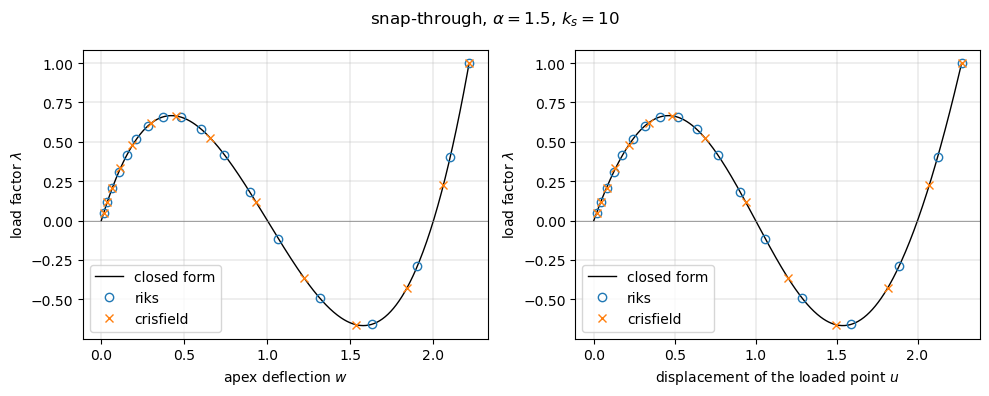

In [3]:
frac, ks = 1.5, 10.
snap = {method: run(method, frac, ks, initialInc=0.05) for method in METHODS}
plot_paths(snap, frac, ks, r'snap-through, $\alpha = 1.5$, $k_s = 10$')

The converged points lie on the closed-form path. The limit point is
estimated from the parabola $\lambda(w)$ through the three converged points
around the largest load factor before $\lambda = 1$; the difference from
the closed form is that of the interpolation between points about one arc
length apart, not an error of the converged points:

In [4]:
rows = path_rows(snap, frac, ks)
for method, (inc, cs) in snap.items():
    w = cs[:, 0]
    i = np.argmax(np.where(inc < 1., inc, -np.inf))
    a, b, c = np.polyfit(w[i-1:i+2], inc[i-1:i+2], 2)
    w_est = -b/(2*a)
    name = method.replace('arc_length_', '')
    rows += [(f'{name}: limit point w_lim (parabola)', w_est, W_LIM),
             (f'{name}: limit load factor (parabola)',
              np.polyval([a, b, c], w_est), 1/frac)]
print()
print_table(rows)

riks: max |lambda - lambda(w)|/max |lambda(w)| over the 18 increments = 4.95e-11
crisfield: max |lambda - lambda(w)|/max |lambda(w)| over the 14 increments = 3.42e-10

quantity                                         computed         reference  rel. diff.
riks: w at lambda = 1                         2.214631461       2.214631461    4.01e-16
riks: u at lambda = 1                         2.272366488       2.272366488    3.91e-16
crisfield: w at lambda = 1                    2.214631461       2.214631461    1.29e-12
crisfield: u at lambda = 1                    2.272366488       2.272366488    1.26e-12
riks: limit point w_lim (parabola)           0.4236739178      0.4226497308    2.42e-03
riks: limit load factor (parabola)           0.6673566037      0.6666666667    1.03e-03
crisfield: limit point w_lim (parabola)      0.4305504122      0.4226497308    1.87e-02
crisfield: limit load factor (parabola)      0.6656359602      0.6666666667    1.55e-03


## Snap-back

A soft spring, $k_s = 0.5$, makes the displacement of the loaded point
decrease along part of the path, $du/dw = 1 + f'(w)/k_s < 0$ around
$w = 1$, where $f'(1) = -1$: the path has limit points in $\lambda$ and in
$u$, a snap-back that neither load control nor the control of $u$ can
trace. The arc length, measured on both degrees of freedom and on the load
factor, passes it:

arc_length_riks       :  22 increments,  103 calls to calc_fint, last load factor 1.0


arc_length_crisfield  :  18 increments,   87 calls to calc_fint, last load factor 1.0


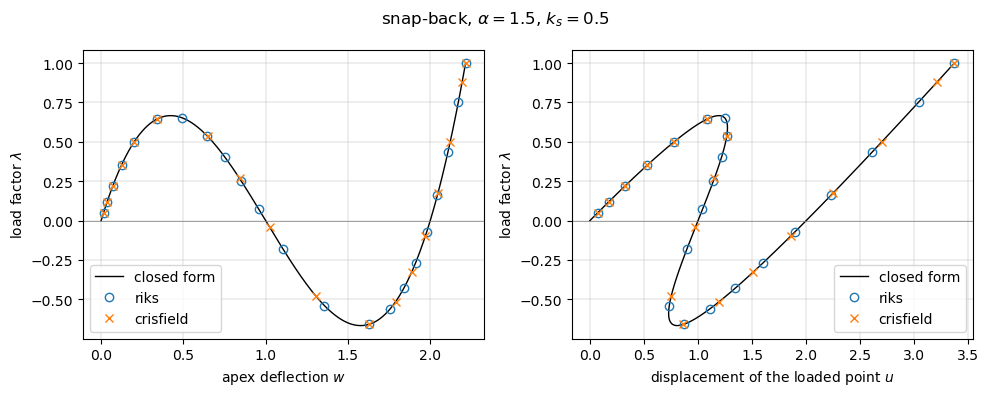

arc_length_riks: increments with a decreasing u: 5
arc_length_crisfield: increments with a decreasing u: 3

riks: max |lambda - lambda(w)|/max |lambda(w)| over the 22 increments = 9.49e-11
crisfield: max |lambda - lambda(w)|/max |lambda(w)| over the 18 increments = 6.29e-11
quantity                            computed         reference  rel. diff.
riks: w at lambda = 1            2.214631461       2.214631461    4.77e-13
riks: u at lambda = 1            3.369331999       3.369331999    3.13e-13
crisfield: w at lambda = 1       2.214631461       2.214631461    8.31e-13
crisfield: u at lambda = 1       3.369331999       3.369331999    5.46e-13


In [5]:
frac, ks = 1.5, 0.5
back = {method: run(method, frac, ks, initialInc=0.05) for method in METHODS}
plot_paths(back, frac, ks, r'snap-back, $\alpha = 1.5$, $k_s = 0.5$')
for method, (inc, cs) in back.items():
    print(f'{method}: increments with a decreasing u: '
          f'{np.sum(np.diff(cs[:, 1]) < 0)}')
print()
print_table(path_rows(back, frac, ks))

## Long steps through the limit point

At 10 times the limit load, $\alpha = 10$, $k_s = 1$, with
`initialInc=0.2`, the steps are long compared with the region of the limit
point. The previous converged point is at the distance of the arc length
from the last one, and the iterations of a step may converge to it, which
would trace the path backwards, the load factor decreasing below zero
without ever reaching 1.0. Such a step, whose increment points against the
tangent predictor, is repeated with a shorter arc length: the apex
deflection increases at every converged increment and the path reaches
$\lambda = 1$:

arc_length_riks       :  16 increments,   92 calls to calc_fint, last load factor 1.0


arc_length_crisfield  :  11 increments,   60 calls to calc_fint, last load factor 1.0


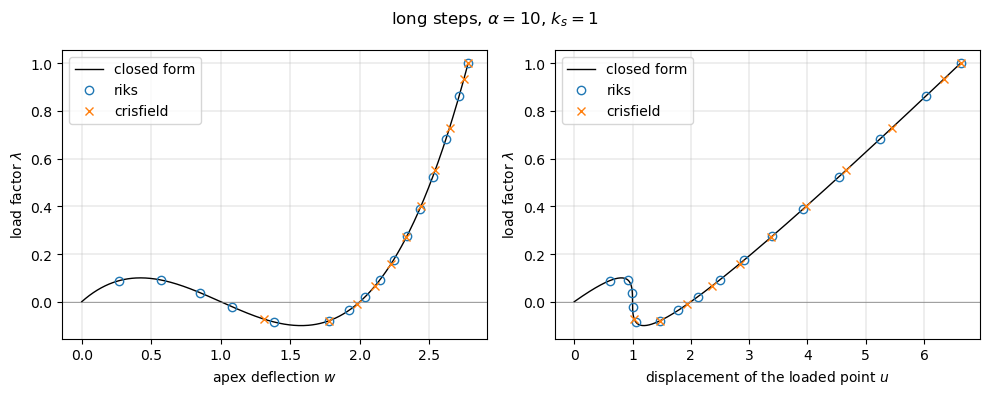

arc_length_riks: apex deflection increasing at every increment: True
arc_length_crisfield: apex deflection increasing at every increment: True

riks: max |lambda - lambda(w)|/max |lambda(w)| over the 16 increments = 9.33e-10
crisfield: max |lambda - lambda(w)|/max |lambda(w)| over the 11 increments = 1.40e-09
quantity                            computed         reference  rel. diff.
riks: w at lambda = 1            2.778735039       2.778735039    2.07e-12
riks: u at lambda = 1            6.627736833       6.627736833    8.70e-13
crisfield: w at lambda = 1       2.778735039       2.778735039    8.99e-13
crisfield: u at lambda = 1       6.627736833       6.627736833    3.77e-13


In [6]:
frac, ks = 10., 1.
long_steps = {method: run(method, frac, ks, initialInc=0.2)
              for method in METHODS}
plot_paths(long_steps, frac, ks, r'long steps, $\alpha = 10$, $k_s = 1$')
for method, (inc, cs) in long_steps.items():
    print(f'{method}: apex deflection increasing at every increment: '
          f'{bool(np.all(np.diff(np.r_[0., cs[:, 0]]) > 0))}')
print()
print_table(path_rows(long_steps, frac, ks))